# Đánh giá hiệu năng và độ bền vững đối kháng của các mô hình NIDS

Notebook đánh giá **LightGBM, Random Forest và XGBoost** trên tập test sạch và toàn bộ các tập Parquet đã biến đổi (đều ở **thang đo đã scale**).

Quy trình:
1. Nạp dữ liệu và ba mô hình.
2. Kiểm tra schema, feature và khả năng đối chiếu từng dòng giữa dữ liệu sạch/biến đổi.
3. Đánh giá từng mô hình trên từng dataset.
4. Tổng hợp baseline, robustness, recall theo loại tấn công, confusion matrix và biểu đồ.

**Lưu ý:** Notebook không fit lại scaler và không scale lại dữ liệu. Các Parquet đầu vào phải được scale bằng scaler tương ứng với quá trình huấn luyện mô hình.

## 1. Cấu hình đường dẫn

- `CLEAN_FILE`: dữ liệu sạch `test_scaled.parquet`.
- `PERTURBED_DIR`: thư mục chứa các tập dữ liệu biến đổi đã scale.
- Notebook tự động lấy **chỉ các file có đuôi `.parquet`** trực tiếp trong `PERTURBED_DIR`.
- `MODEL_DIR`: thư mục chứa ba artifact `.joblib`.
- Nếu chạy trên Google Colab, hãy mount Google Drive trước khi chạy cell cấu hình.


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
from pathlib import Path
import time
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    average_precision_score, roc_auc_score,
    precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

# ====== CHỈNH CÁC ĐƯỜNG DẪN NÀY ======
# Đảm bảo đã mount Google Drive trước khi chạy cell này.
DATA_DIR = Path("/content")
MODEL_DIR = Path("/content")
CLEAN_FILE = DATA_DIR / "test_scaled.parquet"

# Thư mục chứa các dataset đã biến đổi (đã scale).
PERTURBED_DIR = Path(
    "/content/drive/MyDrive/NTTU/HK1-2027/TTTN/"
    "[DTG_TTTN]_NIDS_Adversarial_Robustness_Team/"
    "04_Quality_Assurance_QC/tạo biến đổi feature/"
    "A_day_based/1_11/perturbed_test"
)

MODEL_FILES = {
    "LightGBM": MODEL_DIR / "lightgbm.joblib",
    "Random Forest": MODEL_DIR / "random_forest.joblib",
    "XGBoost": MODEL_DIR / "xgboost.joblib",
}

TARGET_COL = "Label_binary"  # 0 = Benign, 1 = Attack
POSITIVE_LABEL = 1
OUTPUT_DIR = Path("/content/eval_robustness_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert CLEAN_FILE.is_file(), f"Không tìm thấy tập test sạch: {CLEAN_FILE}"
assert PERTURBED_DIR.is_dir(), f"Không tìm thấy thư mục dữ liệu biến đổi: {PERTURBED_DIR}"

for name, path in MODEL_FILES.items():
    assert Path(path).is_file(), f"Không tìm thấy model {name}: {path}"

# Chỉ lấy file có phần mở rộng .parquet (không phân biệt chữ hoa/thường).
PERTURBED_FILES = sorted(
    p for p in PERTURBED_DIR.iterdir()
    if p.is_file() and p.suffix.lower() == ".parquet"
)

print("Clean:", CLEAN_FILE)
print("Thư mục dữ liệu biến đổi:", PERTURBED_DIR)
print("Số tập biến đổi (.parquet):", len(PERTURBED_FILES))
for p in PERTURBED_FILES:
    print(" -", p.name)
print("Models:")
for name, path in MODEL_FILES.items():
    print(f" - {name}: {path}")

if not PERTURBED_FILES:
    raise FileNotFoundError(
        f"Không tìm thấy file .parquet nào trong thư mục: {PERTURBED_DIR}"
    )


Clean: /content/test_scaled.parquet
Thư mục dữ liệu biến đổi: /content/drive/MyDrive/NTTU/HK1-2027/TTTN/[DTG_TTTN]_NIDS_Adversarial_Robustness_Team/04_Quality_Assurance_QC/tạo biến đổi feature/A_day_based/1_11/perturbed_test
Số tập biến đổi (.parquet): 6
 - test_padding_random_16B.parquet
 - test_padding_random_256B.parquet
 - test_padding_random_64B.parquet
 - test_padding_static_16B.parquet
 - test_padding_static_256B.parquet
 - test_padding_static_64B.parquet
Models:
 - LightGBM: /content/lightgbm.joblib
 - Random Forest: /content/random_forest.joblib
 - XGBoost: /content/xgboost.joblib


## 2. Nạp dữ liệu và mô hình

Mỗi artifact mô hình được kỳ vọng là dictionary có hai khóa `model` và `features`. Danh sách feature trong artifact được dùng làm chuẩn về tên và thứ tự cột đầu vào.

In [4]:
def load_dataset(path, dataset_name):
    df = pd.read_parquet(path)
    required = {TARGET_COL}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"{dataset_name} thiếu cột bắt buộc: {sorted(missing)}")

    df = df.reset_index(drop=True)
    df[TARGET_COL] = pd.to_numeric(df[TARGET_COL], errors="raise").astype(int)
    if not df[TARGET_COL].isin([0, 1]).all():
        raise ValueError(f"{dataset_name}: {TARGET_COL} phải chỉ gồm 0 và 1.")
    return df


datasets = {"Test sạch": load_dataset(CLEAN_FILE, "Test sạch")}
for path in PERTURBED_FILES:
    name = Path(path).stem
    if name in datasets:
        raise ValueError(f"Tên dataset bị trùng: {name}")
    datasets[name] = load_dataset(path, name)

models = {}
for model_name, model_path in MODEL_FILES.items():
    artifact = joblib.load(model_path)
    if not isinstance(artifact, dict) or not {"model", "features"}.issubset(artifact):
        raise ValueError(
            f"Artifact {model_name} phải là dict gồm 'model' và 'features'."
        )
    models[model_name] = {
        "estimator": artifact["model"],
        "features": list(artifact["features"]),
    }

# Xác nhận ba mô hình dùng cùng danh sách và thứ tự feature.
reference_features = models[next(iter(models))]["features"]
for model_name, info in models.items():
    if info["features"] != reference_features:
        raise ValueError(f"Feature hoặc thứ tự feature của {model_name} không khớp mô hình đầu tiên.")

for dataset_name, df in datasets.items():
    missing = [c for c in reference_features if c not in df.columns]
    if missing:
        raise ValueError(f"{dataset_name} thiếu {len(missing)} feature: {missing[:20]}")
    X = df[reference_features].apply(pd.to_numeric, errors="coerce")
    if not np.isfinite(X.to_numpy(dtype=float)).all():
        raise ValueError(f"{dataset_name} có NaN/Inf hoặc feature không phải số.")
    datasets[dataset_name] = df

schema_summary = pd.DataFrame([
    {"Dataset": name, "Rows": len(df), "Features": len(reference_features),
     "Benign": int((df[TARGET_COL] == 0).sum()),
     "Attack": int((df[TARGET_COL] == 1).sum())}
    for name, df in datasets.items()
])
display(schema_summary)
print("Đã nạp", len(models), "mô hình và", len(datasets), "dataset.")


,Dataset,Rows,Features,Benign,Attack
0,Test sạch,620183,82,517754,102429
1,test_padding_random_16B,620183,82,517754,102429
2,test_padding_random_256B,620183,82,517754,102429
3,test_padding_random_64B,620183,82,517754,102429
4,test_padding_static_16B,620183,82,517754,102429
5,test_padding_static_256B,620183,82,517754,102429
6,test_padding_static_64B,620183,82,517754,102429


Đã nạp 3 mô hình và 7 dataset.


## 3. Kiểm tra khả năng đối chiếu dữ liệu sạch và dữ liệu biến đổi

ASR và perturbation norms cần so sánh cùng một flow trước/sau biến đổi. Vì vậy, notebook kiểm tra số dòng, nhãn và thứ tự dòng. Nếu không xác nhận được sự tương ứng, các chỉ số cần đối chiếu theo dòng sẽ để `NaN` thay vì tính sai.

`__orig_row` (nếu có) được kiểm tra để bảo đảm thứ tự gốc. Nếu tập biến đổi có `row_id` giống tập sạch, cột này cũng được dùng để đối chiếu.

In [5]:
clean_df = datasets["Test sạch"]

def check_row_alignment(clean, perturbed):
    """Xác nhận cùng flow và cùng thứ tự chỉ dựa trên binary label/row identifier."""
    if len(clean) != len(perturbed):
        return False, "khác số dòng"
    if not np.array_equal(clean[TARGET_COL].to_numpy(), perturbed[TARGET_COL].to_numpy()):
        return False, "Label_binary không cùng thứ tự"
    if "row_id" in clean.columns and "row_id" in perturbed.columns:
        if not np.array_equal(clean["row_id"].to_numpy(), perturbed["row_id"].to_numpy()):
            return False, "row_id không cùng thứ tự"
        return True, "đã xác nhận bằng row_id"
    if "__orig_row" in perturbed.columns:
        orig = perturbed["__orig_row"].to_numpy()
        if not np.array_equal(orig, np.arange(len(clean))):
            return False, "__orig_row không khớp thứ tự dòng gốc"
        return True, "đã xác nhận bằng __orig_row"
    return False, "không có row_id/__orig_row để xác nhận cùng flow"

alignment = {}
for name, df in datasets.items():
    alignment[name] = (True, "tập tham chiếu") if name == "Test sạch" else check_row_alignment(clean_df, df)

alignment_df = pd.DataFrame([
    {"Dataset": name, "Aligned with clean": ok, "Reason": reason}
    for name, (ok, reason) in alignment.items()
])
display(alignment_df)

unaligned = [name for name, (ok, _) in alignment.items() if not ok and name != "Test sạch"]
if unaligned:
    print("LƯU Ý: Các dataset sau không đủ điều kiện tính ASR/norms theo cặp:", unaligned)


,Dataset,Aligned with clean,Reason
0,Test sạch,True,tập tham chiếu
1,test_padding_random_16B,True,đã xác nhận bằng __orig_row
2,test_padding_random_256B,True,đã xác nhận bằng __orig_row
3,test_padding_random_64B,True,đã xác nhận bằng __orig_row
4,test_padding_static_16B,True,đã xác nhận bằng __orig_row
5,test_padding_static_256B,True,đã xác nhận bằng __orig_row
6,test_padding_static_64B,True,đã xác nhận bằng __orig_row


## 4. Hàm dự đoán và tính metrics

### 4.1 Binary Clean Detection Performance

Chỉ đánh giá hai lớp `Benign = 0` và `Attack = 1`, trong đó Attack là positive class. Metrics gồm ROC-AUC, PR-AUC, Precision, Recall/TPR, Binary F1 và FPR. Không tính Macro F1 hoặc metrics phân tách theo subtype của Attack. Accuracy không được dùng làm chỉ số chính.

### 4.2 Adversarial Robustness

- **ASR:** Trong các flow Attack được mô hình phát hiện đúng trên tập sạch, tỷ lệ bị phân loại thành Benign trên tập biến đổi.
- **Robust F1 / Robust Recall:** Binary F1 và Recall của lớp Attack trên tập biến đổi.
- **Δ%:** Mức suy giảm tương đối của metric sau biến đổi so với tập sạch; số dương thể hiện suy giảm.
- **TSR:** Chỉ tính khi có dữ liệu dự đoán/nguồn surrogate và target tương ứng. Nếu không có, để `NaN`.

### 4.3 Perturbation & Validity

L0, L2, L∞ được tính trên chênh lệch feature đã scale, chỉ trên những flow có ít nhất một feature thay đổi. Validity Ratio chỉ được báo cáo khi dataset có cột `__validation_failed`; không tự suy diễn tính hợp lệ vật lý từ feature đã scale.


In [6]:
def get_positive_scores(estimator, X):
    """Trả về score cho lớp Attack=1; dùng cho ROC-AUC và PR-AUC."""
    if hasattr(estimator, "predict_proba"):
        proba = estimator.predict_proba(X)
        classes = list(getattr(estimator, "classes_", [0, 1]))
        if POSITIVE_LABEL not in classes:
            raise ValueError(f"Không tìm thấy lớp positive={POSITIVE_LABEL} trong classes_={classes}")
        return np.asarray(proba)[:, classes.index(POSITIVE_LABEL)]
    if hasattr(estimator, "decision_function"):
        scores = np.asarray(estimator.decision_function(X))
        if scores.ndim == 2:
            classes = list(getattr(estimator, "classes_", [0, 1]))
            return scores[:, classes.index(POSITIVE_LABEL)]
        return scores
    return None


def evaluate_predictions(y_true, y_pred, y_score=None):
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    fpr = fp / (fp + tn) if (fp + tn) else np.nan
    result = {
        "ROC_AUC": roc_auc_score(y_true, y_score) if y_score is not None and len(np.unique(y_true)) == 2 else np.nan,
        "PR_AUC": average_precision_score(y_true, y_score) if y_score is not None and len(np.unique(y_true)) == 2 else np.nan,
        "Precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "Recall_TPR": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "Binary_F1": f1_score(y_true, y_pred, pos_label=1, average="binary", zero_division=0),
        "FPR": fpr,
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
    }
    return result


def predict_one(estimator, X):
    start = time.perf_counter()
    y_pred = np.asarray(estimator.predict(X)).astype(int)
    latency_ms_flow = (time.perf_counter() - start) * 1000 / max(len(X), 1)
    y_score = get_positive_scores(estimator, X)
    return y_pred, y_score, latency_ms_flow


def perturbation_metrics(clean, perturbed, feature_names):
    delta = perturbed[feature_names].to_numpy(dtype=float) - clean[feature_names].to_numpy(dtype=float)
    abs_delta = np.abs(delta)
    changed = np.any(abs_delta > 1e-12, axis=1)
    if not changed.any():
        l0 = l2 = linf = np.nan
    else:
        l0 = float(np.count_nonzero(abs_delta[changed] > 1e-12, axis=1).mean())
        l2 = float(np.linalg.norm(delta[changed], ord=2, axis=1).mean())
        linf = float(abs_delta[changed].max(axis=1).mean())
    return {
        "N_perturbed_flows": int(changed.sum()),
        "L0_mean_changed_flows": l0,
        "L2_mean_changed_flows": l2,
        "Linf_mean_changed_flows": linf,
    }


def validity_metrics(df):
    if "__validation_failed" not in df.columns:
        return {"Validity_Ratio": np.nan, "Constraint_Violation_Rate": np.nan}
    failed = df["__validation_failed"].fillna(True).astype(bool).to_numpy()
    violation_rate = float(failed.mean())
    return {"Validity_Ratio": 1.0 - violation_rate,
            "Constraint_Violation_Rate": violation_rate}


def relative_drop(clean_value, perturbed_value):
    if pd.isna(clean_value) or pd.isna(perturbed_value) or clean_value == 0:
        return np.nan
    return (clean_value - perturbed_value) / abs(clean_value) * 100

## 5. Chạy đánh giá: từng mô hình × từng dataset

Notebook dự đoán nhãn nhị phân cho cả ba mô hình trên tập sạch và từng tập biến đổi. Các dự đoán được lưu để tái sử dụng khi tính ASR và confusion matrix.


In [7]:
predictions = {}  # Binary predictions[(model_name, dataset_name)]
metric_rows = []

for model_name, info in models.items():
    estimator = info["estimator"]
    features = info["features"]
    for dataset_name, df in datasets.items():
        X = df[features]
        y_true = df[TARGET_COL].to_numpy(dtype=int)
        y_pred, y_score, latency = predict_one(estimator, X)
        scores = evaluate_predictions(y_true, y_pred, y_score)
        predictions[(model_name, dataset_name)] = {
            "y_true": y_true, "y_pred": y_pred, "y_score": y_score,
            "latency_ms_flow": latency,
        }
        metric_rows.append({
            "Model": model_name, "Dataset": dataset_name,
            **scores, "Inference_ms_per_flow": latency,
        })

all_metrics = pd.DataFrame(metric_rows)
print("Hoàn tất dự đoán cho", len(models) * len(datasets), "cặp model-dataset.")
display(all_metrics.round(5))
all_metrics.to_csv(OUTPUT_DIR / "all_detection_metrics.csv", index=False)

Hoàn tất dự đoán cho 21 cặp model-dataset.


,Model,Dataset,ROC_AUC,PR_AUC,Precision,Recall_TPR,Binary_F1,FPR,TN,FP,FN,TP,Inference_ms_per_flow
0,LightGBM,Test sạch,0.98735,0.97147,0.40000,0.00002,0.00004,0.00001,517751,3,102427,2,0.01056
1,LightGBM,test_padding_random_16B,0.68751,0.29419,0.00000,0.00000,0.00000,0.00000,517754,0,102429,0,0.00725
2,LightGBM,test_padding_random_256B,0.68751,0.29419,0.00000,0.00000,0.00000,0.00000,517754,0,102429,0,0.00737
3,LightGBM,test_padding_random_64B,0.68751,0.29419,0.00000,0.00000,0.00000,0.00000,517754,0,102429,0,0.01018
4,LightGBM,test_padding_static_16B,0.68751,0.29419,0.00000,0.00000,0.00000,0.00000,517754,0,102429,0,0.00862
5,LightGBM,test_padding_static_256B,0.68751,0.29419,0.00000,0.00000,0.00000,0.00000,517754,0,102429,0,0.00728
6,LightGBM,test_padding_static_64B,0.68751,0.29419,0.00000,0.00000,0.00000,0.00000,517754,0,102429,0,0.00757
7,Random Forest,Test sạch,0.97780,0.96285,1.00000,0.65853,0.79412,0.00000,517754,0,34976,67453,0.00963
8,Random Forest,test_padding_random_16B,0.69350,0.26113,0.00038,0.00008,0.00013,0.04102,496517,21237,102421,8,0.00347
9,Random Forest,test_padding_random_256B,0.69350,0.26113,0.00038,0.00008,0.00013,0.04102,496517,21237,102421,8,0.00480


## 6. Bảng 1 — Baseline Clean Performance

So sánh ba mô hình trên tập `Test sạch` bằng các metrics nhị phân. Inference latency được giữ như chỉ số vận hành bổ sung.


,Model,ROC_AUC,PR_AUC,Precision,Recall_TPR,Binary_F1,FPR,Inference_ms_per_flow
14,XGBoost,0.99332,0.97915,0.99376,0.01089,0.02154,0.00001,0.00719
0,LightGBM,0.98735,0.97147,0.40000,0.00002,0.00004,0.00001,0.01056
7,Random Forest,0.97780,0.96285,1.00000,0.65853,0.79412,0.00000,0.00963


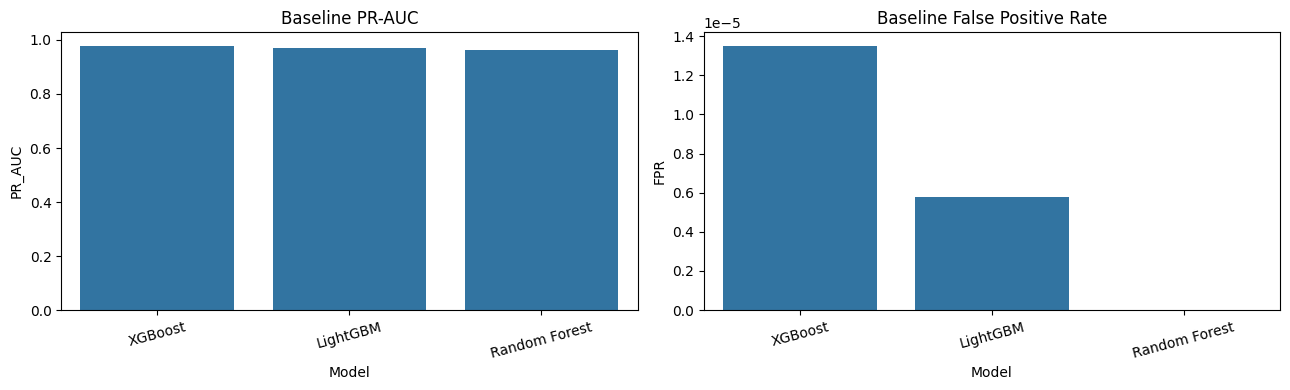

In [8]:
baseline_df = all_metrics[all_metrics["Dataset"] == "Test sạch"].copy()
baseline_columns = ["Model", "ROC_AUC", "PR_AUC", "Precision", "Recall_TPR",
                    "Binary_F1", "FPR", "Inference_ms_per_flow"]
baseline_table = baseline_df[baseline_columns].sort_values("PR_AUC", ascending=False)
display(baseline_table.round(5))
baseline_table.to_csv(OUTPUT_DIR / "table_1_baseline_clean.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(data=baseline_table, x="Model", y="PR_AUC", ax=axes[0])
axes[0].set_title("Baseline PR-AUC")
axes[0].tick_params(axis="x", rotation=15)
sns.barplot(data=baseline_table, x="Model", y="FPR", ax=axes[1])
axes[1].set_title("Baseline False Positive Rate")
axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()


## 7. Bảng 2 — Adversarial Robustness

ASR được tính theo cặp flow: mẫu Attack phải được mô hình dự đoán đúng là Attack trên tập sạch, sau đó mới xét có bị phân loại thành Benign trên tập biến đổi hay không. Với dataset không bảo đảm alignment, ASR và perturbation norms sẽ là `NaN`.

TSR được để `NaN` nếu không có kết quả tấn công surrogate/transfer riêng trong dữ liệu đầu vào.

,Model,Dataset,ASR,Robust_F1,Robust_Recall,Clean_F1,Clean_Recall,Delta_F1_pct,Delta_Recall_pct,N_perturbed_flows,L0_mean_changed_flows,L2_mean_changed_flows,Linf_mean_changed_flows,Validity_Ratio,Constraint_Violation_Rate,TSR
0,LightGBM,test_padding_random_16B,1.0,0.00000,0.00000,0.00004,0.00002,100.00000,100.00000,620183,79.0,4.846587e+07,2.830993e+07,1.0,0.0,NaN
1,LightGBM,test_padding_random_256B,1.0,0.00000,0.00000,0.00004,0.00002,100.00000,100.00000,620183,79.0,4.846591e+07,2.830997e+07,1.0,0.0,NaN
2,LightGBM,test_padding_random_64B,1.0,0.00000,0.00000,0.00004,0.00002,100.00000,100.00000,620183,79.0,4.846588e+07,2.830994e+07,1.0,0.0,NaN
3,LightGBM,test_padding_static_16B,1.0,0.00000,0.00000,0.00004,0.00002,100.00000,100.00000,620183,79.0,4.846587e+07,2.830994e+07,1.0,0.0,NaN
4,LightGBM,test_padding_static_256B,1.0,0.00000,0.00000,0.00004,0.00002,100.00000,100.00000,620183,79.0,4.846595e+07,2.831001e+07,1.0,0.0,NaN
5,LightGBM,test_padding_static_64B,1.0,0.00000,0.00000,0.00004,0.00002,100.00000,100.00000,620183,79.0,4.846589e+07,2.830995e+07,1.0,0.0,NaN
6,Random Forest,test_padding_random_16B,1.0,0.00013,0.00008,0.79412,0.65853,99.98371,99.98814,620183,79.0,4.846587e+07,2.830993e+07,1.0,0.0,NaN
7,Random Forest,test_padding_random_256B,1.0,0.00013,0.00008,0.79412,0.65853,99.98371,99.98814,620183,79.0,4.846591e+07,2.830997e+07,1.0,0.0,NaN
8,Random Forest,test_padding_random_64B,1.0,0.00013,0.00008,0.79412,0.65853,99.98371,99.98814,620183,79.0,4.846588e+07,2.830994e+07,1.0,0.0,NaN
9,Random Forest,test_padding_static_16B,1.0,0.00013,0.00008,0.79412,0.65853,99.98371,99.98814,620183,79.0,4.846587e+07,2.830994e+07,1.0,0.0,NaN


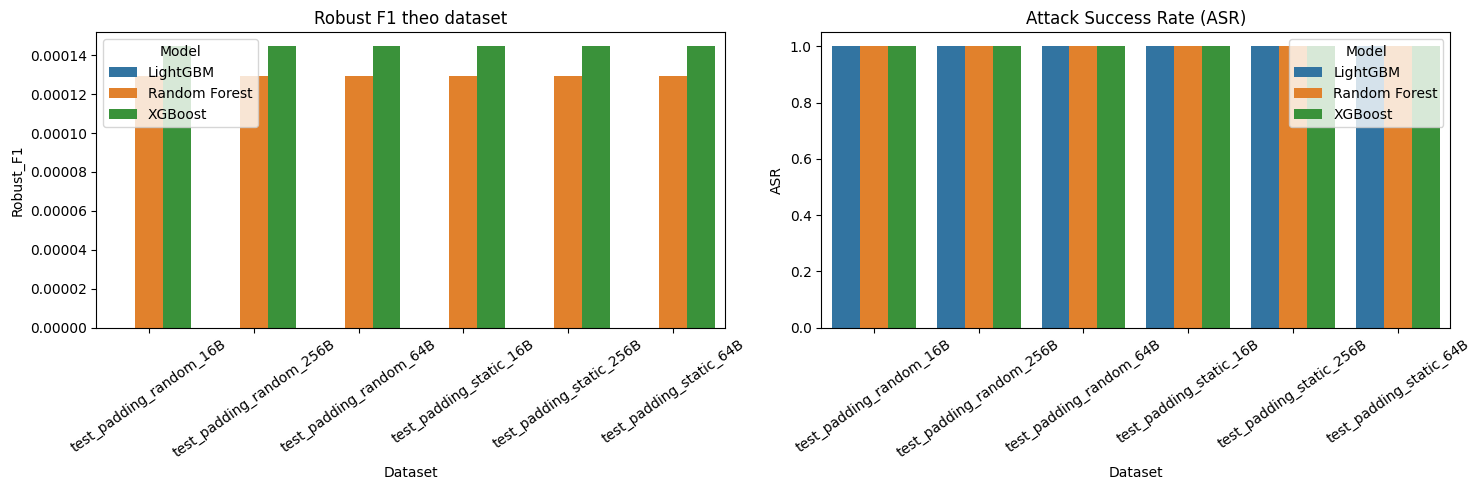

In [9]:
robust_rows = []
clean_metric_lookup = {
    (r["Model"], r["Dataset"]): r
    for _, r in all_metrics.iterrows()
}

for model_name in models:
    clean_pred = predictions[(model_name, "Test sạch")]
    clean_df_for_model = datasets["Test sạch"]
    clean_y = clean_pred["y_true"]
    clean_hat = clean_pred["y_pred"]
    clean_row = clean_metric_lookup[(model_name, "Test sạch")]

    for dataset_name, df in datasets.items():
        if dataset_name == "Test sạch":
            continue
        pred_info = predictions[(model_name, dataset_name)]
        row = clean_metric_lookup[(model_name, dataset_name)]
        aligned, _ = alignment[dataset_name]

        asr = np.nan
        perturb = {"N_perturbed_flows": np.nan, "L0_mean_changed_flows": np.nan,
                   "L2_mean_changed_flows": np.nan, "Linf_mean_changed_flows": np.nan}
        if aligned:
            eligible = (clean_y == 1) & (clean_hat == 1)
            denominator = int(eligible.sum())
            successful_evasion = int(((pred_info["y_pred"] == 0) & eligible).sum())
            asr = successful_evasion / denominator if denominator else np.nan
            perturb = perturbation_metrics(
                clean_df_for_model, df, models[model_name]["features"]
            )

        valid = validity_metrics(df)
        robust_rows.append({
            "Model": model_name,
            "Dataset": dataset_name,
            "ASR": asr,
            "Robust_F1": row["Binary_F1"],
            "Robust_Recall": row["Recall_TPR"],
            "Clean_F1": clean_row["Binary_F1"],
            "Clean_Recall": clean_row["Recall_TPR"],
            "Delta_F1_pct": relative_drop(clean_row["Binary_F1"], row["Binary_F1"]),
            "Delta_Recall_pct": relative_drop(clean_row["Recall_TPR"], row["Recall_TPR"]),
            **perturb, **valid,
            "TSR": np.nan,  # Chỉ có thể tính khi cung cấp kết quả surrogate -> target.
        })

robustness_table = pd.DataFrame(robust_rows)
display(robustness_table.round(5))
robustness_table.to_csv(OUTPUT_DIR / "table_2_adversarial_robustness.csv", index=False)

if len(robustness_table):
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    sns.barplot(data=robustness_table, x="Dataset", y="Robust_F1", hue="Model", ax=axes[0])
    axes[0].set_title("Robust F1 theo dataset")
    axes[0].tick_params(axis="x", rotation=35)
    sns.barplot(data=robustness_table, x="Dataset", y="ASR", hue="Model", ax=axes[1])
    axes[1].set_title("Attack Success Rate (ASR)")
    axes[1].tick_params(axis="x", rotation=35)
    plt.tight_layout(); plt.show()

## 8. Bảng 3 — Perturbation & Validity Analysis

Bảng này tổng hợp chi phí nhiễu và tính hợp lệ theo từng dataset biến đổi. Các norm chỉ được tính khi xác nhận được alignment giữa tập sạch và tập biến đổi.


,Dataset,Aligned_with_clean,Alignment_reason,N_perturbed_flows,L0_mean_changed_flows,L2_mean_changed_flows,Linf_mean_changed_flows,Validity_Ratio,Constraint_Violation_Rate
0,test_padding_random_16B,True,đã xác nhận bằng __orig_row,620183,79.0,4.846587e+07,2.830993e+07,1.0,0.0
1,test_padding_random_256B,True,đã xác nhận bằng __orig_row,620183,79.0,4.846591e+07,2.830997e+07,1.0,0.0
2,test_padding_random_64B,True,đã xác nhận bằng __orig_row,620183,79.0,4.846588e+07,2.830994e+07,1.0,0.0
3,test_padding_static_16B,True,đã xác nhận bằng __orig_row,620183,79.0,4.846587e+07,2.830994e+07,1.0,0.0
4,test_padding_static_256B,True,đã xác nhận bằng __orig_row,620183,79.0,4.846595e+07,2.831001e+07,1.0,0.0
5,test_padding_static_64B,True,đã xác nhận bằng __orig_row,620183,79.0,4.846589e+07,2.830995e+07,1.0,0.0


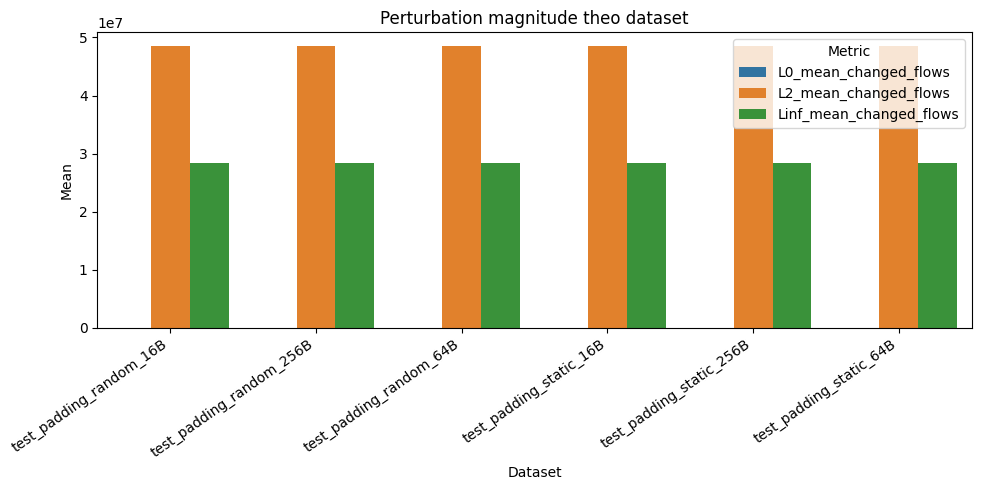

In [10]:
perturbation_rows = []
clean_df_for_norms = datasets["Test sạch"]

for dataset_name, df in datasets.items():
    if dataset_name == "Test sạch":
        continue

    aligned, alignment_reason = alignment[dataset_name]
    if aligned:
        perturb = perturbation_metrics(clean_df_for_norms, df, reference_features)
    else:
        perturb = {
            "N_perturbed_flows": np.nan,
            "L0_mean_changed_flows": np.nan,
            "L2_mean_changed_flows": np.nan,
            "Linf_mean_changed_flows": np.nan,
        }

    perturbation_rows.append({
        "Dataset": dataset_name,
        "Aligned_with_clean": aligned,
        "Alignment_reason": alignment_reason,
        **perturb,
        **validity_metrics(df),
    })

perturbation_table = pd.DataFrame(perturbation_rows)
display(perturbation_table.round(6))
perturbation_table.to_csv(OUTPUT_DIR / "table_3_perturbation_validity.csv", index=False)

if len(perturbation_table):
    norm_cols = ["L0_mean_changed_flows", "L2_mean_changed_flows", "Linf_mean_changed_flows"]
    plot_df = perturbation_table.melt(
        id_vars="Dataset", value_vars=norm_cols,
        var_name="Metric", value_name="Mean"
    ).dropna()
    if len(plot_df):
        plt.figure(figsize=(max(10, 1.2 * len(perturbation_table)), 5))
        sns.barplot(data=plot_df, x="Dataset", y="Mean", hue="Metric")
        plt.title("Perturbation magnitude theo dataset")
        plt.xticks(rotation=35, ha="right")
        plt.tight_layout(); plt.show()


## 9. Confusion Matrix và Classification Report

Mỗi mô hình được hiển thị confusion matrix trên từng dataset. Các ma trận được lưu thành ảnh để đưa vào báo cáo.

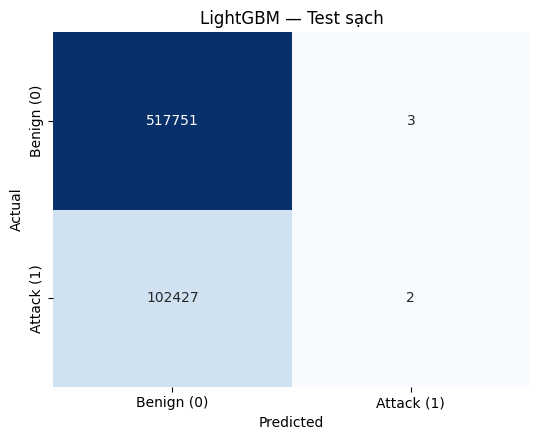


===== LightGBM | Test sạch =====
              precision    recall  f1-score   support

      Benign       0.83      1.00      0.91    517754
      Attack       0.40      0.00      0.00    102429

    accuracy                           0.83    620183
   macro avg       0.62      0.50      0.46    620183
weighted avg       0.76      0.83      0.76    620183



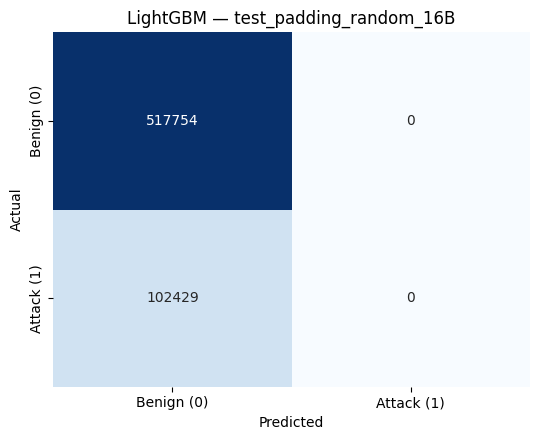


===== LightGBM | test_padding_random_16B =====
              precision    recall  f1-score   support

      Benign       0.83      1.00      0.91    517754
      Attack       0.00      0.00      0.00    102429

    accuracy                           0.83    620183
   macro avg       0.42      0.50      0.45    620183
weighted avg       0.70      0.83      0.76    620183



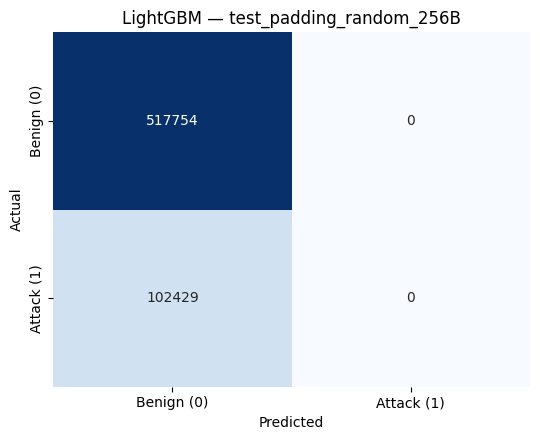


===== LightGBM | test_padding_random_256B =====
              precision    recall  f1-score   support

      Benign       0.83      1.00      0.91    517754
      Attack       0.00      0.00      0.00    102429

    accuracy                           0.83    620183
   macro avg       0.42      0.50      0.45    620183
weighted avg       0.70      0.83      0.76    620183



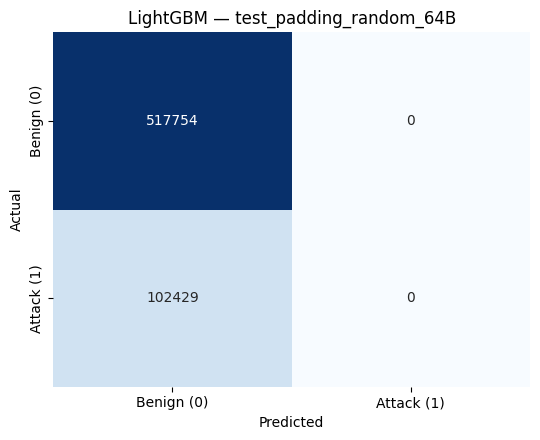


===== LightGBM | test_padding_random_64B =====
              precision    recall  f1-score   support

      Benign       0.83      1.00      0.91    517754
      Attack       0.00      0.00      0.00    102429

    accuracy                           0.83    620183
   macro avg       0.42      0.50      0.45    620183
weighted avg       0.70      0.83      0.76    620183



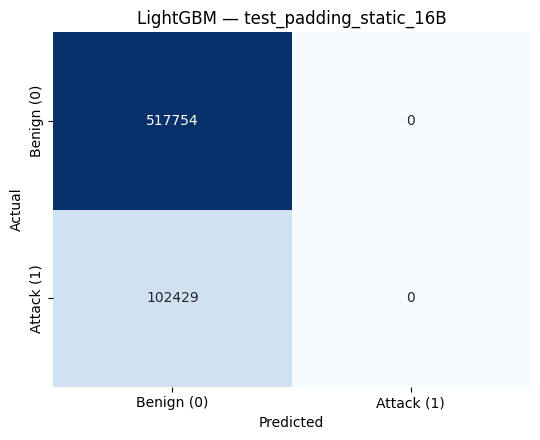


===== LightGBM | test_padding_static_16B =====
              precision    recall  f1-score   support

      Benign       0.83      1.00      0.91    517754
      Attack       0.00      0.00      0.00    102429

    accuracy                           0.83    620183
   macro avg       0.42      0.50      0.45    620183
weighted avg       0.70      0.83      0.76    620183



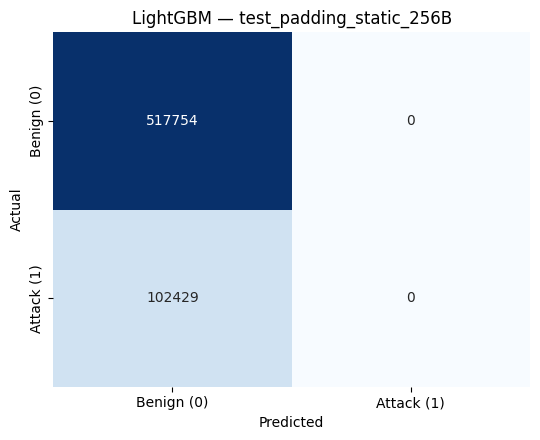


===== LightGBM | test_padding_static_256B =====
              precision    recall  f1-score   support

      Benign       0.83      1.00      0.91    517754
      Attack       0.00      0.00      0.00    102429

    accuracy                           0.83    620183
   macro avg       0.42      0.50      0.45    620183
weighted avg       0.70      0.83      0.76    620183



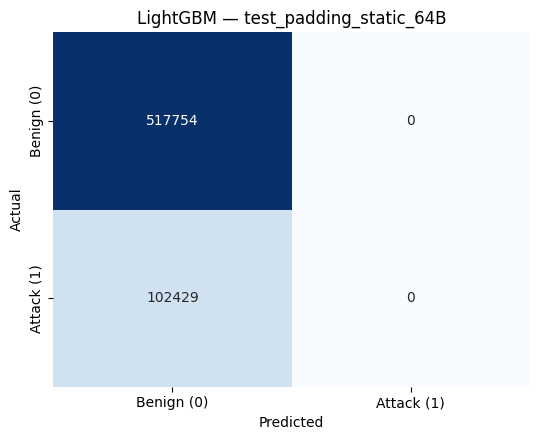


===== LightGBM | test_padding_static_64B =====
              precision    recall  f1-score   support

      Benign       0.83      1.00      0.91    517754
      Attack       0.00      0.00      0.00    102429

    accuracy                           0.83    620183
   macro avg       0.42      0.50      0.45    620183
weighted avg       0.70      0.83      0.76    620183



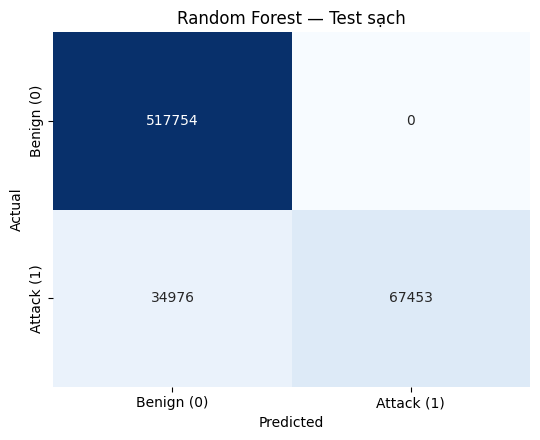


===== Random Forest | Test sạch =====
              precision    recall  f1-score   support

      Benign       0.94      1.00      0.97    517754
      Attack       1.00      0.66      0.79    102429

    accuracy                           0.94    620183
   macro avg       0.97      0.83      0.88    620183
weighted avg       0.95      0.94      0.94    620183



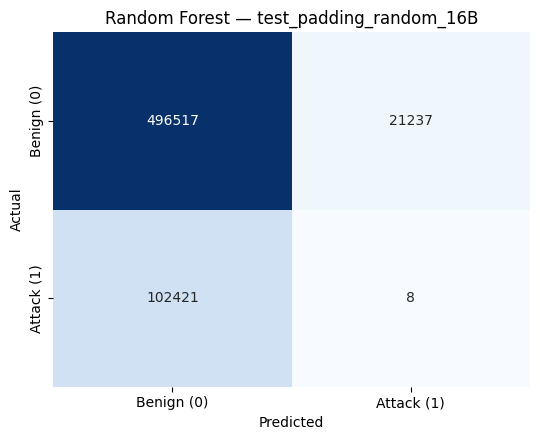


===== Random Forest | test_padding_random_16B =====
              precision    recall  f1-score   support

      Benign       0.83      0.96      0.89    517754
      Attack       0.00      0.00      0.00    102429

    accuracy                           0.80    620183
   macro avg       0.41      0.48      0.44    620183
weighted avg       0.69      0.80      0.74    620183



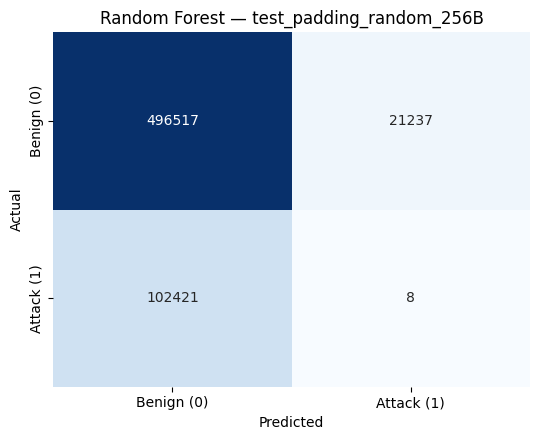


===== Random Forest | test_padding_random_256B =====
              precision    recall  f1-score   support

      Benign       0.83      0.96      0.89    517754
      Attack       0.00      0.00      0.00    102429

    accuracy                           0.80    620183
   macro avg       0.41      0.48      0.44    620183
weighted avg       0.69      0.80      0.74    620183



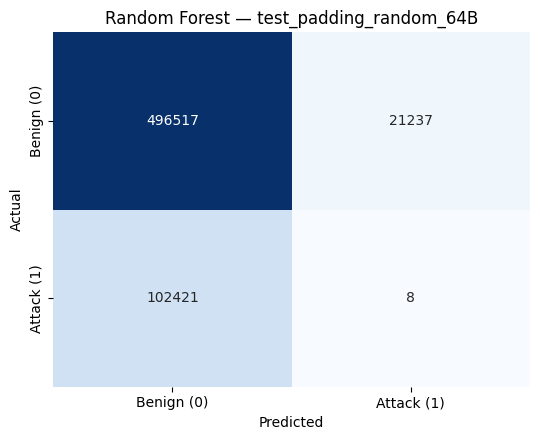


===== Random Forest | test_padding_random_64B =====
              precision    recall  f1-score   support

      Benign       0.83      0.96      0.89    517754
      Attack       0.00      0.00      0.00    102429

    accuracy                           0.80    620183
   macro avg       0.41      0.48      0.44    620183
weighted avg       0.69      0.80      0.74    620183



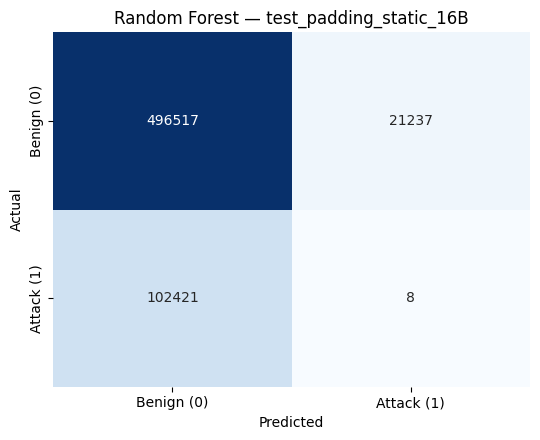


===== Random Forest | test_padding_static_16B =====
              precision    recall  f1-score   support

      Benign       0.83      0.96      0.89    517754
      Attack       0.00      0.00      0.00    102429

    accuracy                           0.80    620183
   macro avg       0.41      0.48      0.44    620183
weighted avg       0.69      0.80      0.74    620183



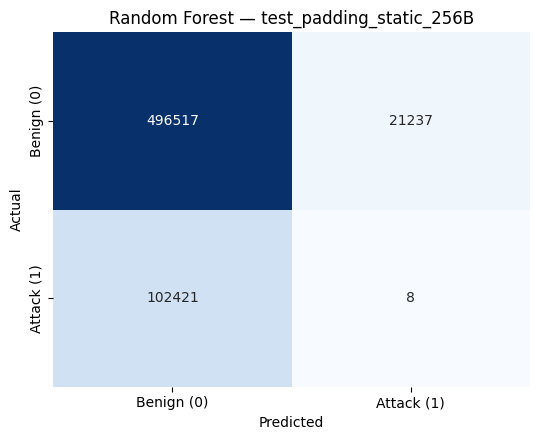


===== Random Forest | test_padding_static_256B =====
              precision    recall  f1-score   support

      Benign       0.83      0.96      0.89    517754
      Attack       0.00      0.00      0.00    102429

    accuracy                           0.80    620183
   macro avg       0.41      0.48      0.44    620183
weighted avg       0.69      0.80      0.74    620183



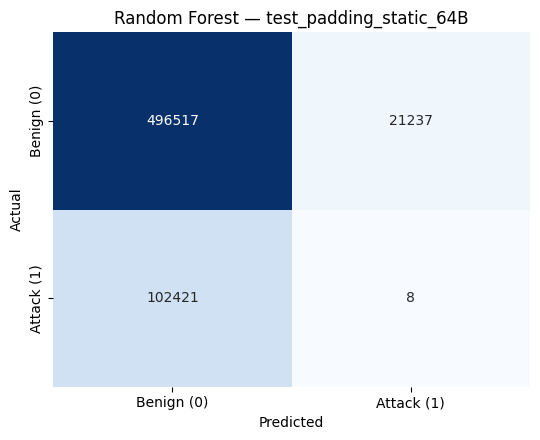


===== Random Forest | test_padding_static_64B =====
              precision    recall  f1-score   support

      Benign       0.83      0.96      0.89    517754
      Attack       0.00      0.00      0.00    102429

    accuracy                           0.80    620183
   macro avg       0.41      0.48      0.44    620183
weighted avg       0.69      0.80      0.74    620183



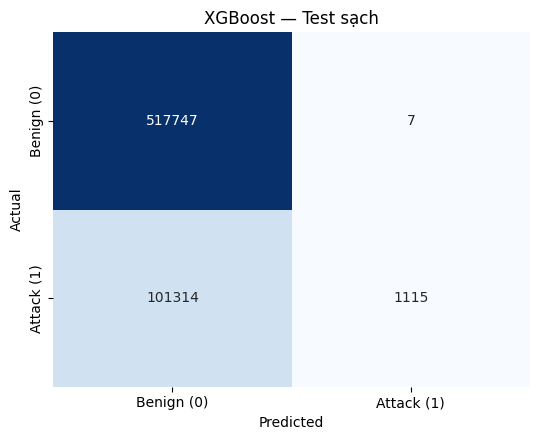


===== XGBoost | Test sạch =====
              precision    recall  f1-score   support

      Benign       0.84      1.00      0.91    517754
      Attack       0.99      0.01      0.02    102429

    accuracy                           0.84    620183
   macro avg       0.92      0.51      0.47    620183
weighted avg       0.86      0.84      0.76    620183



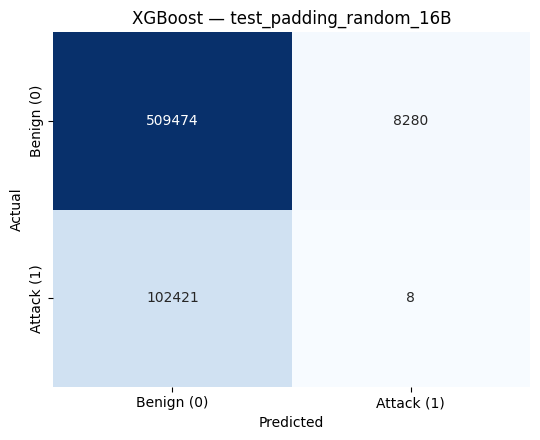


===== XGBoost | test_padding_random_16B =====
              precision    recall  f1-score   support

      Benign       0.83      0.98      0.90    517754
      Attack       0.00      0.00      0.00    102429

    accuracy                           0.82    620183
   macro avg       0.42      0.49      0.45    620183
weighted avg       0.70      0.82      0.75    620183



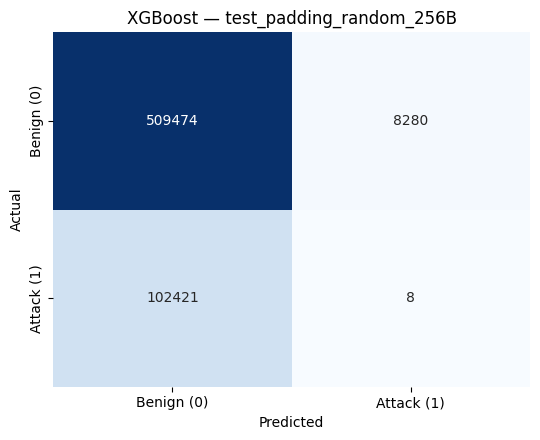


===== XGBoost | test_padding_random_256B =====
              precision    recall  f1-score   support

      Benign       0.83      0.98      0.90    517754
      Attack       0.00      0.00      0.00    102429

    accuracy                           0.82    620183
   macro avg       0.42      0.49      0.45    620183
weighted avg       0.70      0.82      0.75    620183



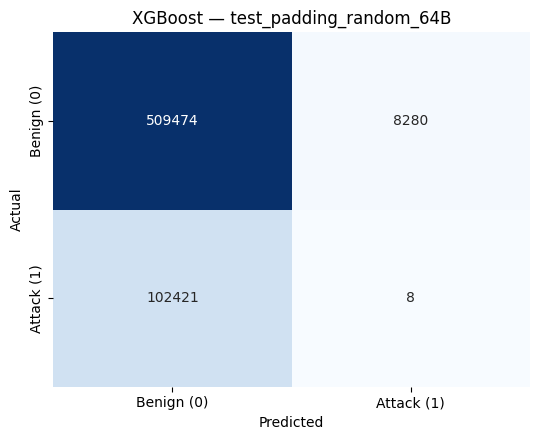


===== XGBoost | test_padding_random_64B =====
              precision    recall  f1-score   support

      Benign       0.83      0.98      0.90    517754
      Attack       0.00      0.00      0.00    102429

    accuracy                           0.82    620183
   macro avg       0.42      0.49      0.45    620183
weighted avg       0.70      0.82      0.75    620183



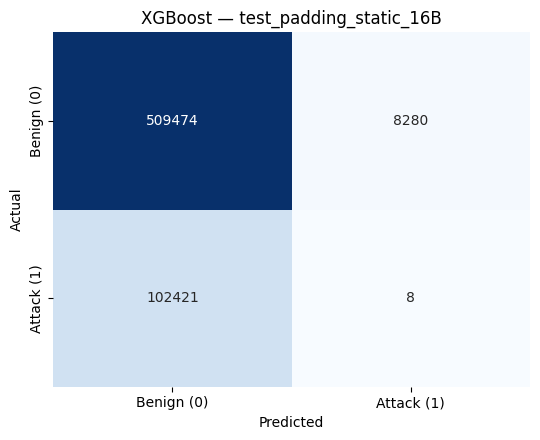


===== XGBoost | test_padding_static_16B =====
              precision    recall  f1-score   support

      Benign       0.83      0.98      0.90    517754
      Attack       0.00      0.00      0.00    102429

    accuracy                           0.82    620183
   macro avg       0.42      0.49      0.45    620183
weighted avg       0.70      0.82      0.75    620183



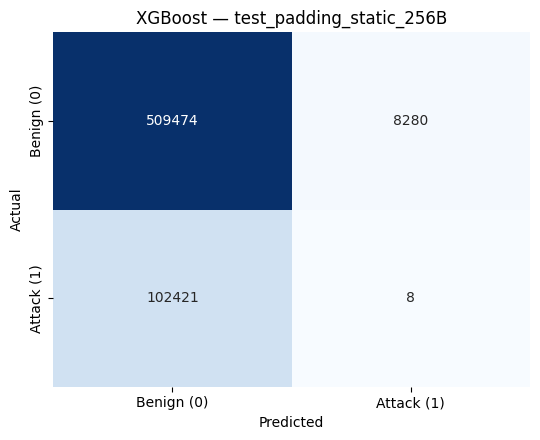


===== XGBoost | test_padding_static_256B =====
              precision    recall  f1-score   support

      Benign       0.83      0.98      0.90    517754
      Attack       0.00      0.00      0.00    102429

    accuracy                           0.82    620183
   macro avg       0.42      0.49      0.45    620183
weighted avg       0.70      0.82      0.75    620183



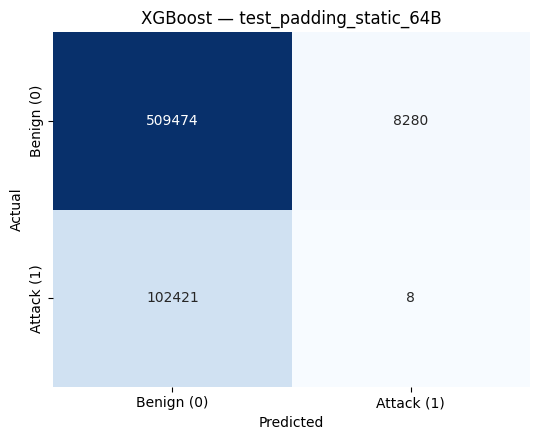


===== XGBoost | test_padding_static_64B =====
              precision    recall  f1-score   support

      Benign       0.83      0.98      0.90    517754
      Attack       0.00      0.00      0.00    102429

    accuracy                           0.82    620183
   macro avg       0.42      0.49      0.45    620183
weighted avg       0.70      0.82      0.75    620183



In [11]:
for model_name in models:
    for dataset_name in datasets:
        info = predictions[(model_name, dataset_name)]
        cm = confusion_matrix(info["y_true"], info["y_pred"], labels=[0, 1])
        fig, ax = plt.subplots(figsize=(5.5, 4.5))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                    xticklabels=["Benign (0)", "Attack (1)"],
                    yticklabels=["Benign (0)", "Attack (1)"], ax=ax)
        ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
        ax.set_title(f"{model_name} — {dataset_name}")
        plt.tight_layout()
        safe_name = "_".join(str(x).replace(" ", "_") for x in [model_name, dataset_name])
        fig.savefig(OUTPUT_DIR / f"confusion_matrix_{safe_name}.png", dpi=160, bbox_inches="tight")
        plt.show()

        print(f"\n===== {model_name} | {dataset_name} =====")
        print(classification_report(
            info["y_true"], info["y_pred"],
            labels=[0, 1], target_names=["Benign", "Attack"], zero_division=0
        ))

## 9. Xuất báo cáo tổng hợp

Các file CSV và hình ảnh được lưu trong `OUTPUT_DIR`:
- `table_1_baseline_clean.csv`: hiệu năng nhị phân trên dữ liệu sạch.
- `table_2_adversarial_robustness.csv`: ASR, Robust F1/Recall và mức suy giảm.
- `table_3_perturbation_validity.csv`: L0, L2, L∞ và các chỉ số validity.
- `all_detection_metrics.csv`: metrics nhị phân cho mọi cặp model-dataset.
- Các confusion matrix và `evaluation_manifest.json`.

Các chỉ số không đủ dữ liệu để tính sẽ để `NaN`, không thay bằng 0.


In [12]:
# Bảng tóm tắt trạng thái tính toán, giúp nhận biết metric nào không khả dụng.
summary = {
    "n_models": len(models),
    "n_datasets": len(datasets),
    "n_model_dataset_evaluations": len(all_metrics),
    "n_perturbed_datasets": len(datasets) - 1,
    "n_unaligned_perturbed_datasets": len(unaligned),
    "TSR_available": False,
    "validity_available_datasets": [
        name for name, df in datasets.items() if "__validation_failed" in df.columns
    ],
}
print(summary)

# Lưu thông tin cấu hình và schema để truy vết kết quả.
import json
manifest = {
    "clean_file": str(CLEAN_FILE),
    "perturbed_files": [str(p) for p in PERTURBED_FILES],
    "model_files": {k: str(v) for k, v in MODEL_FILES.items()},
    "features": reference_features,
    "target_col": TARGET_COL,
    "alignment": {k: {"aligned": bool(v[0]), "reason": v[1]} for k, v in alignment.items()},
    "metric_notes": {
        "ASR": "Binary Attack rows correctly detected on clean data that become Benign on perturbed data, requiring row alignment.",
        "TSR": "Not computed; surrogate-to-target transfer results were not supplied.",
        "perturbation_norms": "Computed on scaled binary-flow feature differences for changed flows only, when row alignment is verified.",
        "validity_ratio": "Computed only when __validation_failed is present; no physical validity inferred from scaled features.",
        "classification_scope": "Binary only: Benign=0, Attack=1. Macro F1 and per-attack-type metrics are excluded."
    },
    "summary": summary,
}
with open(OUTPUT_DIR / "evaluation_manifest.json", "w", encoding="utf-8") as f:
    json.dump(manifest, f, ensure_ascii=False, indent=2)

print("Đã lưu toàn bộ kết quả tại:", OUTPUT_DIR)
print("Các file chính:")
for p in sorted(OUTPUT_DIR.iterdir()):
    print(" -", p.name)

{'n_models': 3, 'n_datasets': 7, 'n_model_dataset_evaluations': 21, 'n_perturbed_datasets': 6, 'n_unaligned_perturbed_datasets': 0, 'TSR_available': False, 'validity_available_datasets': ['test_padding_random_16B', 'test_padding_random_256B', 'test_padding_random_64B', 'test_padding_static_16B', 'test_padding_static_256B', 'test_padding_static_64B']}
Đã lưu toàn bộ kết quả tại: /content/eval_robustness_results
Các file chính:
 - all_detection_metrics.csv
 - confusion_matrix_LightGBM_Test_sạch.png
 - confusion_matrix_LightGBM_test_padding_random_16B.png
 - confusion_matrix_LightGBM_test_padding_random_256B.png
 - confusion_matrix_LightGBM_test_padding_random_64B.png
 - confusion_matrix_LightGBM_test_padding_static_16B.png
 - confusion_matrix_LightGBM_test_padding_static_256B.png
 - confusion_matrix_LightGBM_test_padding_static_64B.png
 - confusion_matrix_Random_Forest_Test_sạch.png
 - confusion_matrix_Random_Forest_test_padding_random_16B.png
 - confusion_matrix_Random_Forest_test_paddi